## Part A: Conceptual Understanding

In [76]:
'''
1. What are Supervised Learning Algorithms?
Supervised learning is a type of machine learning in which a model is trained using labelled data. 
It learns from input and output examples to predict results for new data.

2. Difference Between Regression and Classification Algorithms
Regression: Predicts continuous numerical values,example: house prices and salaries.
Classification: Predicts categories or classes,example: spam or not spam, pass or fail.

3. Explain Simple Linear Regression.
Simple Linear Regression is a supervised learning algorithm used to predict a dependent variable using one independent variable. 
It represents the relationship using a straight line: Y = mX + C.

4. List and Explain the Assumptions of Linear Regression.
Linearity: There must be a linear relationship between variables.
Independence: Observations should be independent.
Homoscedasticity: Error variance should remain constant.
Normality: Residuals should be normally distributed.
No Multicollinearity: Independent variables should not be highly correlated with each other.

5. What is Bias-Variance Trade-off?
Bias-Variance Trade-off is the balance between two types of errors in a machine learning model.
High bias causes underfitting, while high variance causes overfitting.
A good model maintains a balance between both.

6. Explain Overfitting and Underfitting with Examples.
Overfitting: When a model performs well on training data but poorly on testing data. Example: A very complex polynomial model memorizing training data.
Underfitting: When a model performs poorly on both training and testing data. Example: Using simple linear regression for a highly non-linear relationship.

'''

'\n1. What are Supervised Learning Algorithms?\nSupervised learning is a type of machine learning in which a model is trained using labelled data. \nIt learns from input and output examples to predict results for new data.\n\n2. Difference Between Regression and Classification Algorithms\nRegression: Predicts continuous numerical values,example: house prices and salaries.\nClassification: Predicts categories or classes,example: spam or not spam, pass or fail.\n\n3. Explain Simple Linear Regression.\nSimple Linear Regression is a supervised learning algorithm used to predict a dependent variable using one independent variable. \nIt represents the relationship using a straight line: Y = mX + C.\n\n4. List and Explain the Assumptions of Linear Regression.\nLinearity: There must be a linear relationship between variables.\nIndependence: Observations should be independent.\nHomoscedasticity: Error variance should remain constant.\nNormality: Residuals should be normally distributed.\nNo Mul

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [78]:
df=pd.read_csv("D:\RealEstate_HousePrice.csv.csv")
df.head()

<>:1: SyntaxWarning: invalid escape sequence '\R'
<>:1: SyntaxWarning: invalid escape sequence '\R'
C:\Users\Admin\AppData\Local\Temp\ipykernel_12012\2694691524.py:1: SyntaxWarning: invalid escape sequence '\R'
  df=pd.read_csv("D:\RealEstate_HousePrice.csv.csv")


,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


### Part B:Dataset understanding and preparation

In [79]:
# 7.
# Dependent Variable
y = df["house_price_inr"]
print(y.name)

# Independent Variables
X = df.drop("house_price_inr", axis=1)
print(X.columns)


house_price_inr
Index(['house_id', 'area_sqft', 'bedrooms', 'bathrooms', 'location_score',
       'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage',
       'has_pool', 'renovation_years_ago'],
      dtype='object')


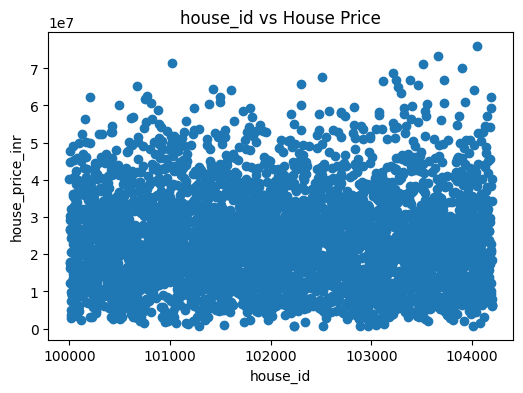

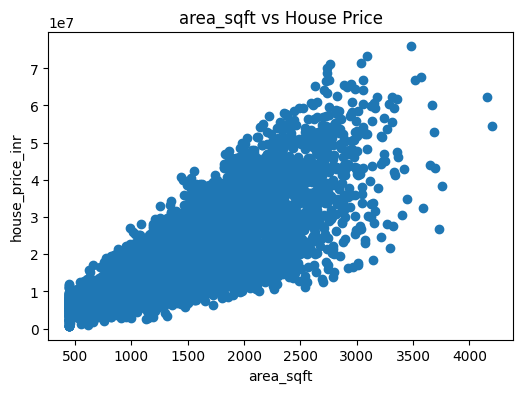

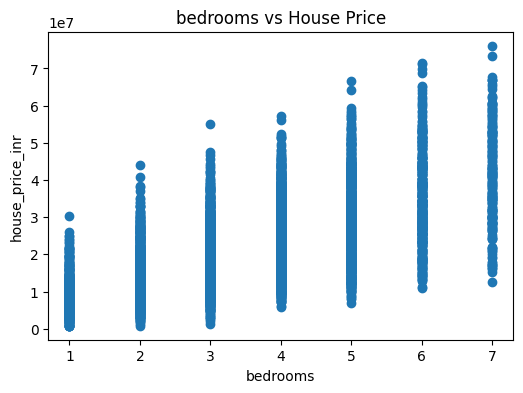

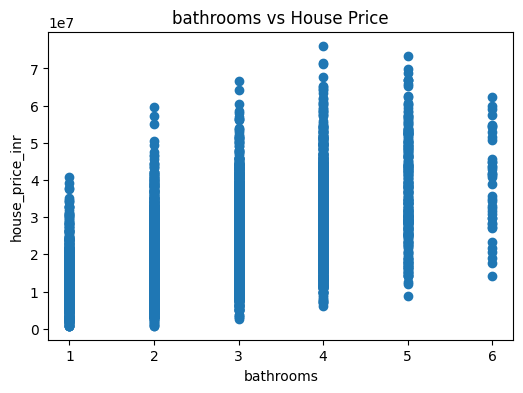

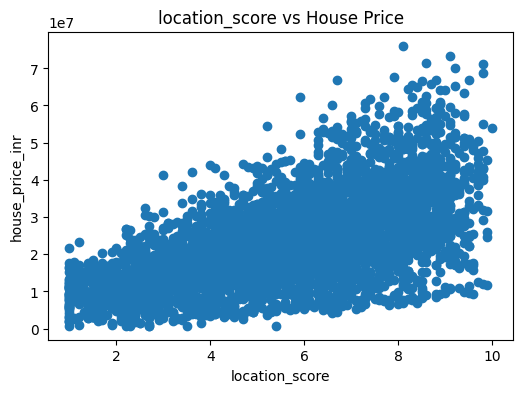

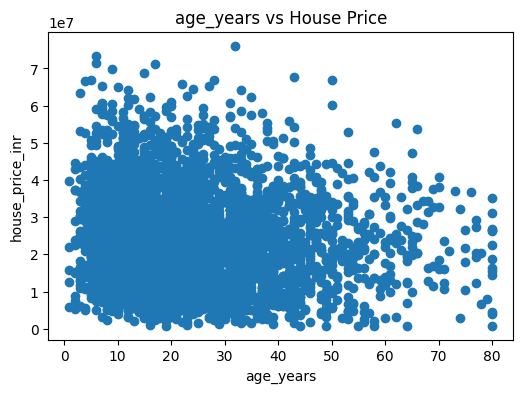

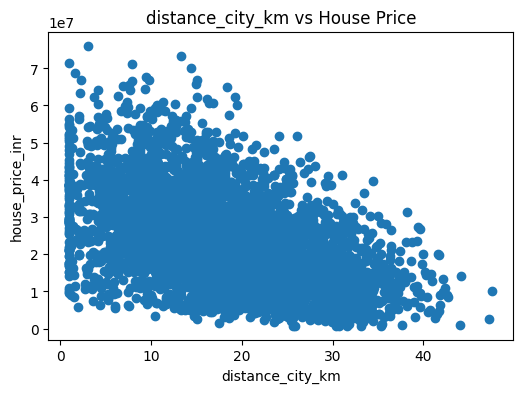

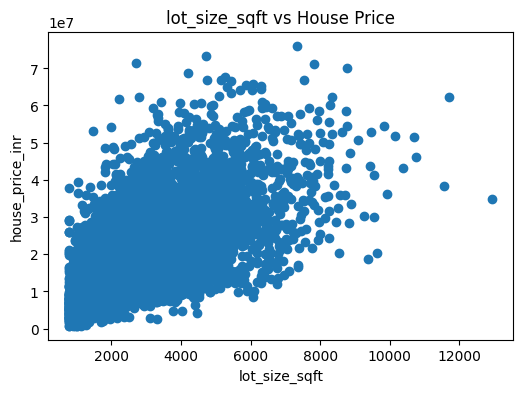

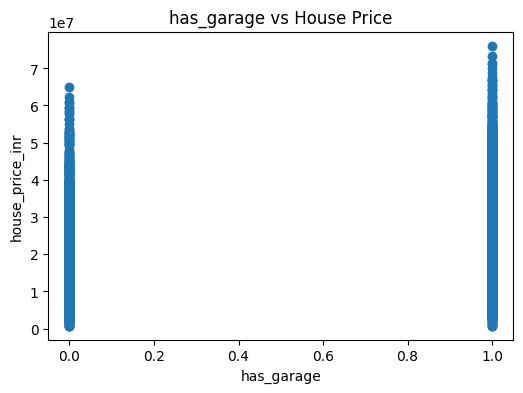

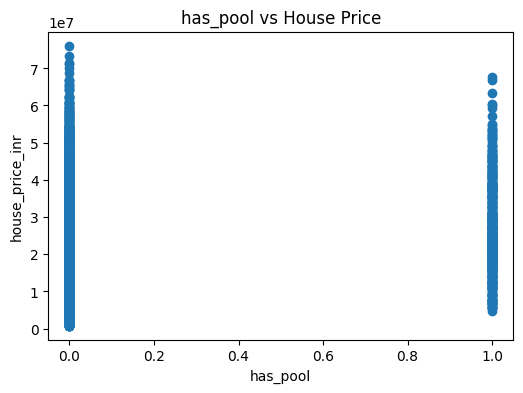

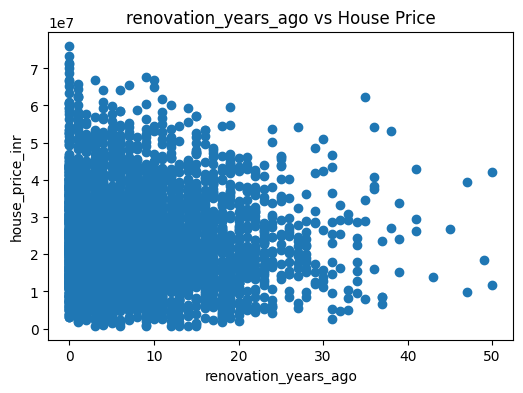

In [80]:
# 8. Visualizing the relationship between features and target variable
for feature in X:
    plt.figure(figsize=(6,4))
    plt.scatter(df[feature], df["house_price_inr"])
    plt.xlabel(feature)
    plt.ylabel("house_price_inr")
    plt.title(f"{feature} vs House Price")

In [81]:
# 9. splitting data
X_train,X_test,y_train,y_test=train_test_split(X, y, test_size=0.20, random_state=42)

### Part C: Simple linear Regression

In [82]:
from sklearn.linear_model import LinearRegression

In [83]:
# 10. simple linear regression
x_train1 = X_train[["area_sqft"]]
x_test1 = X_test[["area_sqft"]]

model = LinearRegression()
model.fit(x_train1, y_train)
y_pred = model.predict(x_test1)

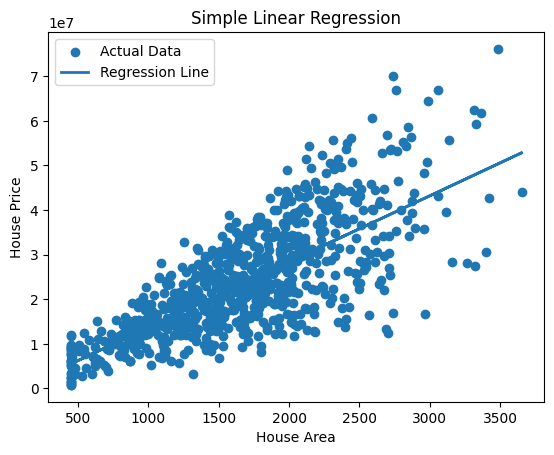

In [84]:
# 11.
# regression line
plt.scatter(x_test1, y_test, label="Actual Data")
plt.plot(x_test1, y_pred, linewidth=2, label="Regression Line")
plt.xlabel("House Area")
plt.ylabel("House Price")
plt.title("Simple Linear Regression")
plt.legend()

In [85]:
#slope
slope = model.coef_[0]
print(f"Slope: {slope}")

# intercept
intercept = model.intercept_
print(f"Intercept: {intercept}")

Slope: 14788.306111307536
Intercept: -1163519.1764186025


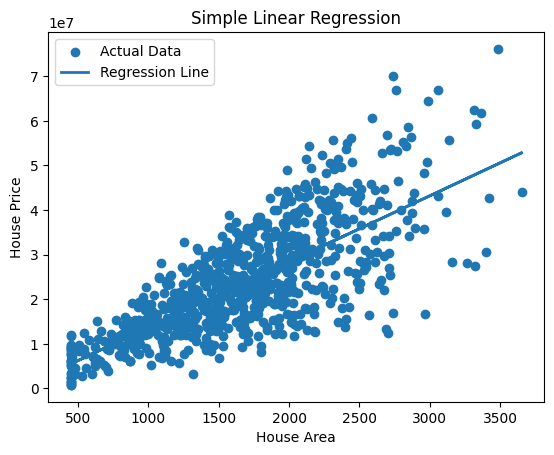

In [86]:
# 12.
# calculating errors
residual=y_test - y_pred

# liner regression assumptions
#1. Linearity
plt.scatter(x_test1, y_test, label="Actual Data")
plt.plot(x_test1, y_pred, linewidth=2, label="Regression Line")
plt.xlabel("House Area")
plt.ylabel("House Price")
plt.title("Simple Linear Regression")
plt.legend()

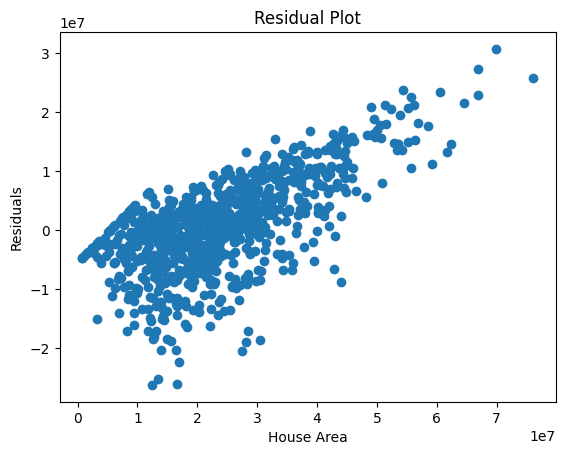

In [87]:
#2. Independence of errors
plt.scatter(y_test, residual)
plt.xlabel("House Area")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

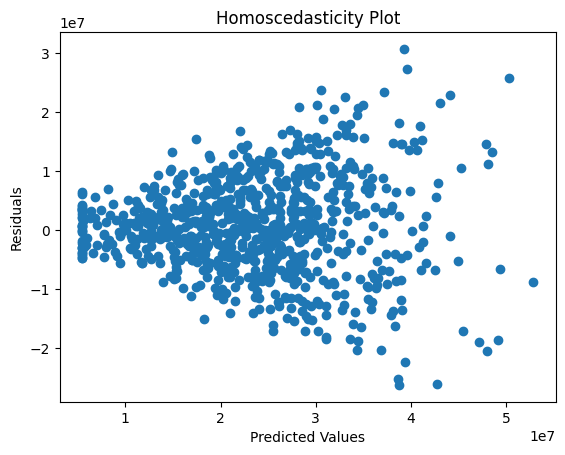

In [88]:
#3. Homoscedasticity
plt.scatter(y_pred, residual)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Homoscedasticity Plot")
plt.show()

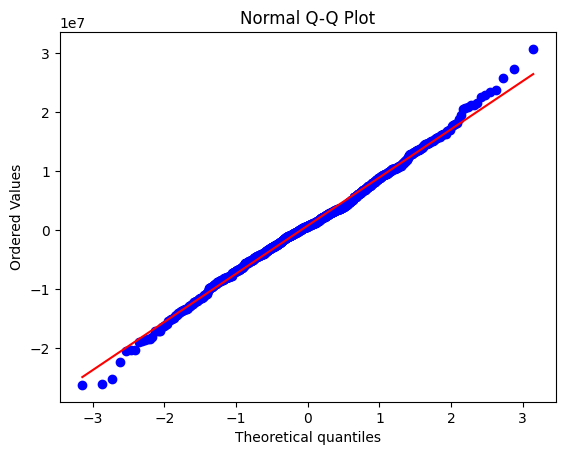

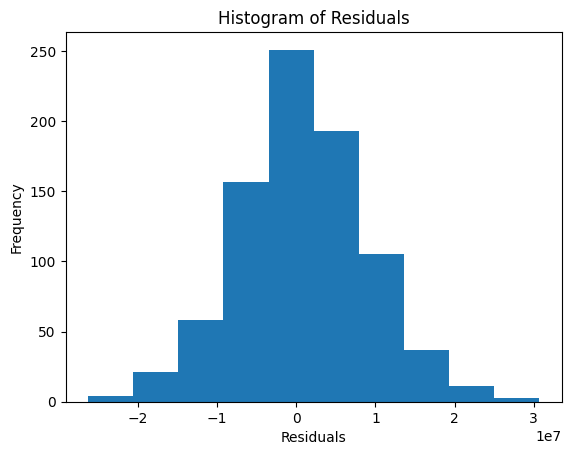

In [89]:
#4. Normality of errors
import scipy.stats as stats
stats.probplot(residual, dist="norm", plot=plt)
plt.title("Normal Q-Q Plot")
plt.show()

plt.hist(residual)
plt.xlabel("Residuals") 
plt.ylabel("Frequency")
plt.title("Histogram of Residuals") 
plt.show()

### Part D: Model Evaluation Metrics

In [90]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [91]:
# 13. Evaluation
# MAE
mae = mean_absolute_error(y_test, y_pred)

# MSE
mse = mean_squared_error(y_test, y_pred)

# RMSE
rmse = np.sqrt(mse)

# R² Score
r2 = r2_score(y_test, y_pred)

# Adjusted R²
n = len(y_test)          
p = X_test.shape[1]      
adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

print("MAE :", mae)
print("MSE :", mse)
print("RMSE :", rmse)
print("R² Score :", r2)
print("Adjusted R² :", adjusted_r2)

MAE : 6294593.696131912
MSE : 66989260021849.47
RMSE : 8184696.696997969
R² Score : 0.5625199587991578
Adjusted R² : 0.556708025884654


In [92]:
# 14. Interpretation of Results
'''
1. MAE (6,294,593.70): The model's predictions differ from actual house prices by an average absolute amount of approximately 6.29 million.

2. MSE (66,989,260,021,849.47): Indicates the average squared prediction error, giving greater weight to large errors.

3. RMSE (8,184,696.70): The root-mean-square prediction error is approximately 8.18 million in house-price units.

4. R² Score (0.5625): The model explains approximately 56.25% of the variation in house prices.

5. Adjusted R² (0.5620): After adjusting for the number of predictors, the model accounts for approximately 56.20% of the variation in house prices.

Conclusion: The model shows a moderate fit, but its prediction errors are relatively large. 
Including additional features, such as location and number of bedrooms, may improve its performance.

'''

"\n1. MAE (6,294,593.70): The model's predictions differ from actual house prices by an average absolute amount of approximately 6.29 million.\n\n2. MSE (66,989,260,021,849.47): Indicates the average squared prediction error, giving greater weight to large errors.\n\n3. RMSE (8,184,696.70): The root-mean-square prediction error is approximately 8.18 million in house-price units.\n\n4. R² Score (0.5625): The model explains approximately 56.25% of the variation in house prices.\n\n5. Adjusted R² (0.5620): After adjusting for the number of predictors, the model accounts for approximately 56.20% of the variation in house prices.\n\nConclusion: The model shows a moderate fit, but its prediction errors are relatively large. \nIncluding additional features, such as location and number of bedrooms, may improve its performance.\n\n"

### Part E: Multiple linear Regression

In [93]:
# 15. multiple linear regression
mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)
y_pred_mlr = mlr_model.predict(X_test)

In [94]:
#  16. evaluation and comparison
# MAE
mae_mlr = mean_absolute_error(y_test, y_pred_mlr)

# MSE
mse_mlr = mean_squared_error(y_test, y_pred_mlr)

# RMSE
rmse_mlr = np.sqrt(mse_mlr)

# R² Score
r2_mlr = r2_score(y_test, y_pred_mlr)

# Adjusted R²
n = len(y_test)
p = X_test.shape[1]
adjusted_r2_mlr = 1 - ((1 - r2_mlr) * (n - 1) / (n - p - 1))

print("Multiple Linear Regression Performance")
print("MAE :", mae_mlr)
print("MSE :", mse_mlr)
print("RMSE :", rmse_mlr)
print("R² Score :", r2_mlr)
print("Adjusted R² :", adjusted_r2_mlr)

Multiple Linear Regression Performance
MAE : 2605648.611505146
MSE : 12597222158307.7
RMSE : 3549256.5641705445
R² Score : 0.9177325847899332
Adjusted R² : 0.9166396601917319


In [95]:
# comparison of simple and multiple linear regression
'''
The Multiple Linear Regression model performed better than Simple Linear Regression because house price depends on several factors, not only area.
The model explained more variance in house prices and reduced prediction error.

'''

'\nThe Multiple Linear Regression model performed better than Simple Linear Regression because house price depends on several factors, not only area.\nThe model explained more variance in house prices and reduced prediction error.\n\n'

In [96]:
# 17. Expalin why the performance improves or degrades
'''
Performance improves because:
Multiple Linear Regression uses more relevant features instead of only area.
House price depends on many factors such as: bedrooms,bathrooms,location,garage,pool,lot size.
More information helps the model make better predictions.
Usually:
R² increases
Adjusted R² increases
Errors (MAE, RMSE, MSE) decrease

Performance may decrease because:
Some features may be irrelevant.
Features may contain noise.
Multicollinearity can occur (features highly related to each other).
Model may slightly overfit training data.

'''

'\nPerformance improves because:\nMultiple Linear Regression uses more relevant features instead of only area.\nHouse price depends on many factors such as: bedrooms,bathrooms,location,garage,pool,lot size.\nMore information helps the model make better predictions.\nUsually:\nR² increases\nAdjusted R² increases\nErrors (MAE, RMSE, MSE) decrease\n\nPerformance may decrease because:\nSome features may be irrelevant.\nFeatures may contain noise.\nMulticollinearity can occur (features highly related to each other).\nModel may slightly overfit training data.\n\n'

### Part F: Polynomial regression

In [97]:
from sklearn.preprocessing import PolynomialFeatures

In [98]:
# 18 .implementation of polynomial regression
poly = PolynomialFeatures(degree=2)
x_train_poly = poly.fit_transform(X_train)
x_test_poly = poly.fit_transform(X_test)
model1 = LinearRegression()
model1.fit(x_train_poly, y_train)
poly_pred = model1.predict(x_test_poly)


In [99]:
# 19.
# evaluation
MAE = mean_absolute_error(y_test, poly_pred)
print("MAE:",MAE)

MSE = mean_squared_error(y_test, poly_pred)
print("MSE:",MSE )

RMSE=np.sqrt(MSE)
print("RMSE:", RMSE)

r2 = r2_score(y_test, poly_pred)
print("R2 Score:", r2)

MAE: 1659159.3088949106
MSE: 5119996285496.729
RMSE: 2262740.878999787
R2 Score: 0.9665633538093017


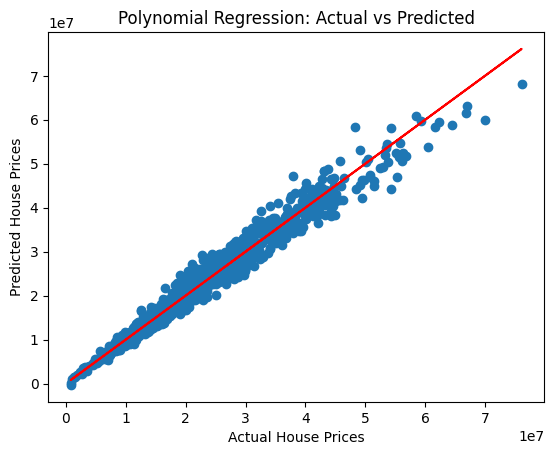

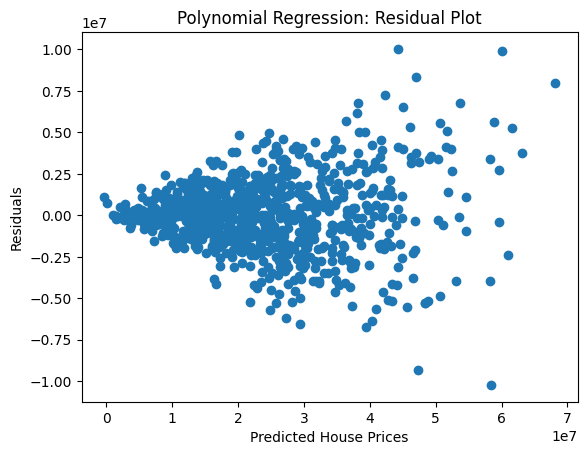

In [100]:
# visualisation
#actual vs predicted house prices
plt.scatter(y_test, poly_pred)
plt.plot(y_test, y_test, color="red")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Polynomial Regression: Actual vs Predicted")
plt.show()

#residual plot
residuals = y_test - poly_pred
plt.scatter(poly_pred, residuals)
plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Polynomial Regression: Residual Plot")
plt.show()

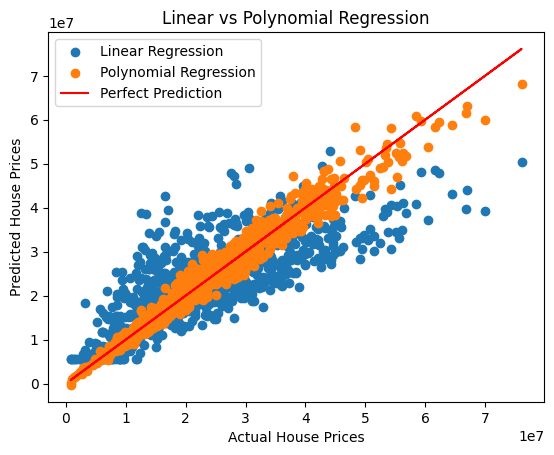

In [101]:
# visual comparison 
plt.scatter(y_test, y_pred, label="Linear Regression")
plt.scatter(y_test, poly_pred, label="Polynomial Regression")

plt.plot(y_test, y_test, color="red", label="Perfect Prediction")

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()

## numerical comparison


In [102]:
'''
1. MAE
Linear Regression: 6,294,593.70
Polynomial Regression: 1,659,159.31
Result: Polynomial Regression has lower average absolute prediction errors.

2. MSE
Linear Regression: 66,989,260,021,849.47
Polynomial Regression: 5,119,996,285,496.73
Result: Polynomial Regression has a much lower squared prediction error.

3. RMSE
Linear Regression: 8,184,696.70
Polynomial Regression: 2,262,740.88
Result: Polynomial Regression has lower root-mean-square prediction errors.

4. R² Score
Linear Regression: 0.5625
Polynomial Regression: 0.9666

Result: Polynomial Regression explains approximately 96.66% of the variation in house prices, compared with 56.25% for Linear Regression.

'''

'\n1. MAE\nLinear Regression: 6,294,593.70\nPolynomial Regression: 1,659,159.31\nResult: Polynomial Regression has lower average absolute prediction errors.\n\n2. MSE\nLinear Regression: 66,989,260,021,849.47\nPolynomial Regression: 5,119,996,285,496.73\nResult: Polynomial Regression has a much lower squared prediction error.\n\n3. RMSE\nLinear Regression: 8,184,696.70\nPolynomial Regression: 2,262,740.88\nResult: Polynomial Regression has lower root-mean-square prediction errors.\n\n4. R² Score\nLinear Regression: 0.5625\nPolynomial Regression: 0.9666\n\nResult: Polynomial Regression explains approximately 96.66% of the variation in house prices, compared with 56.25% for Linear Regression.\n\n'

In [103]:
# 20. identifying signs of underfitting and overfitting
'''
Underfitting:
Training R² is low.
Testing R² is also low.
The model fails to capture the relationship between features and house prices.

Overfitting:
Training R² is very high.
Testing R² is noticeably lower.
The model performs well on training data but poorly on unseen data.

Good Fit:
Training and testing R² are reasonably high.
The difference between the scores is relatively small.
The model generalizes well to unseen data.

'''

'\nUnderfitting:\nTraining R² is low.\nTesting R² is also low.\nThe model fails to capture the relationship between features and house prices.\n\nOverfitting:\nTraining R² is very high.\nTesting R² is noticeably lower.\nThe model performs well on training data but poorly on unseen data.\n\nGood Fit:\nTraining and testing R² are reasonably high.\nThe difference between the scores is relatively small.\nThe model generalizes well to unseen data.\n\n'

In [104]:
# Linear Regression
y_train_pred = model.predict(x_train1)
y_test_pred = model.predict(x_test1)

print("Training R2:", r2_score(y_train, y_train_pred))
print("Testing R2:", r2_score(y_test, y_test_pred))

Training R2: 0.5723074839148459
Testing R2: 0.5625199587991578


In [105]:
# multilinear regression
y_trainmlr_pred = mlr_model.predict(X_train)
y_testmlr_pred = mlr_model.predict(X_test)

print("Training R2 (MLR):", r2_score(y_train, y_trainmlr_pred))
print("Testing R2 (MLR):", r2_score(y_test, y_testmlr_pred))

Training R2 (MLR): 0.9247229954670411
Testing R2 (MLR): 0.9177325847899332


In [106]:
# polynomial regression
y_train_poly_pred = model1.predict(x_train_poly)
y_test_poly_pred = model1.predict(x_test_poly)

print("Training R2 (Polynomial):", r2_score(y_train, y_train_poly_pred))
print("Testing R2 (Polynomial):", r2_score(y_test, y_test_poly_pred))

Training R2 (Polynomial): 0.9685274436626854
Testing R2 (Polynomial): 0.9665633538093017


In [107]:
'''
Simple Linear Regression: Underfitting.

Multiple Linear Regression (MLR): Good fit.

Polynomial Regression: Good fit,better than MLR

'''

'\nSimple Linear Regression: Underfitting.\n\nMultiple Linear Regression (MLR): Good fit.\n\nPolynomial Regression: Good fit,better than MLR\n\n'

### Part G: Gradient descent optimization

### 21. Explanation


In [108]:
'''
Gradient Descent is an optimization algorithm used in Machine Learning to:
1. Minimize the error (cost function)
2. Find best model parameters (weights)
Gradient Descent updates parameters step-by-step to reduce prediction error.

How it works:
Initialize model parameters.
Calculate the prediction error.
Calculate the gradient to determine the direction of error reduction.
Update parameters using the learning rate.
Repeat until the error is minimized or the algorithm converges.

Example: Like walking down a hill to reach its lowest point, Gradient Descent adjusts model parameters to find the minimum error.
Learning Rate: Controls the size of each update.

'''

'\nGradient Descent is an optimization algorithm used in Machine Learning to:\n1. Minimize the error (cost function)\n2. Find best model parameters (weights)\nGradient Descent updates parameters step-by-step to reduce prediction error.\n\nHow it works:\nInitialize model parameters.\nCalculate the prediction error.\nCalculate the gradient to determine the direction of error reduction.\nUpdate parameters using the learning rate.\nRepeat until the error is minimized or the algorithm converges.\n\nExample: Like walking down a hill to reach its lowest point, Gradient Descent adjusts model parameters to find the minimum error.\nLearning Rate: Controls the size of each update.\n\n'

In [109]:
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler

In [110]:
# scaling the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)    


In [111]:
# 23. Stochastic Gradient Descent (SGD) Regression
model_sgd = SGDRegressor(max_iter=1000, learning_rate='constant', random_state=42)
model_sgd.fit(X_train_scaled, y_train)
sgd_pred = model_sgd.predict(X_test_scaled)

In [112]:
# evaluation
mae_sgd = mean_absolute_error(y_test, sgd_pred)
print("Mean Absolute Error (SGD):", mae_sgd)

mse_sgd = mean_squared_error(y_test, sgd_pred)
print("Mean Squared Error (SGD):", mse_sgd)

rmse_sgd = np.sqrt(mse_sgd)
print("Root Mean Squared Error (SGD):", rmse_sgd)

r2_sgd = r2_score(y_test, sgd_pred)
print("R² Score (SGD):", r2_sgd)


Mean Absolute Error (SGD): 2636558.8221937288
Mean Squared Error (SGD): 12823980248435.656
Root Mean Squared Error (SGD): 3581058.5374209755
R² Score (SGD): 0.9162517184752517


## Part H: Bias-Variance and Model Diagnostics

In [113]:
# 26. analyze bias n variance
# Simple linear regression
rmse_train_linear = np.sqrt(mean_squared_error(model.predict(x_train1), y_train))
print("Bias (Simple Linear Regression):", rmse_train_linear)
rmse_test_linear = np.sqrt(mean_squared_error(model.predict(x_test1), y_test))
print("Variance (Simple Linear Regression):", rmse_test_linear ,"\n")

# multiple linear regression
rmse_train_mlr = np.sqrt(mean_squared_error(mlr_model.predict(X_train), y_train))
print("Bias (Multiple Linear Regression):", rmse_train_mlr)
rmse_test_mlr = np.sqrt(mean_squared_error(mlr_model.predict(X_test), y_test))
print("Variance (Multiple Linear Regression):", rmse_test_mlr,"\n")

# polynomial regression
rmse_train_poly = np.sqrt(mean_squared_error(model1.predict(x_train_poly), y_train))
print("Bias (Polynomial Regression):", rmse_train_poly)
rmse_test_poly = np.sqrt(mean_squared_error(model1.predict(x_test_poly), y_test))
print("Variance (Polynomial Regression):", rmse_test_poly)

Bias (Simple Linear Regression): 8104428.03525333
Variance (Simple Linear Regression): 8184696.696997969 

Bias (Multiple Linear Regression): 3400068.8334513423
Variance (Multiple Linear Regression): 3549256.5641705445 

Bias (Polynomial Regression): 2198480.1795675782
Variance (Polynomial Regression): 2262740.878999787


In [114]:
# 27. Explain how model complexity affects prediction error
'''
Model complexity affects how well a model learns patterns from data.

Low complexity: High training and testing error → Underfitting.
Medium complexity: Low training and testing error → Good fit.
High complexity: Very low training error but high testing error → Overfitting.

In short: Increasing complexity initially reduces prediction error, but too much complexity can increase testing error
'''

'\nModel complexity affects how well a model learns patterns from data.\n\nLow complexity: High training and testing error → Underfitting.\nMedium complexity: Low training and testing error → Good fit.\nHigh complexity: Very low training error but high testing error → Overfitting.\n\nIn short: Increasing complexity initially reduces prediction error, but too much complexity can increase testing error\n'

In [115]:
# 28. identify which model best balances bias and variance
'''
Simple Linear Regression: Highest bias and variance, indicating underfitting.
Multiple Linear Regression: Better balance than simple linear regression.
Polynomial Regression: Lowest bias and variance, giving the best balance among the three models.

Therefore, Polynomial Regression is the best-performing model based on these values
'''

'\nSimple Linear Regression: Highest bias and variance, indicating underfitting.\nMultiple Linear Regression: Better balance than simple linear regression.\nPolynomial Regression: Lowest bias and variance, giving the best balance among the three models.\n\nTherefore, Polynomial Regression is the best-performing model based on these values\n'

## Part I: Final Analysis n Reporting

In [116]:
# 29. summarize
'''
1. Best performing Model n y?
Polynomial Regression performed the best with an R² score of 0.9666.
It has the highest accuracy and lowest prediction errors because it captures non-linear relationships between features and house prices.

2. impact of Gradient Descent optimization
Gradient Descent helps minimize prediction errors by updating model parameters. 
SGDRegressor achieved an R² score of 0.9163, showing good predictive performance.

3. evidence of underfitting or overfitting
Simple Linear Regression: Underfitting due to low R² scores n high error (8184696.696997969 n 0.5625199587991578 respectively).
Multiple Linear Regression: Good fit with a small difference between training and testing scores(3400068.8334513423 n 3549256.5641705445) and R2 score(0.9177325847899332).
Polynomial Regression: Good fit with high R²(0.9665633538093017) scores and less errors (2262740.878999787 n 2198480.1795675782),no significant evidence of overfitting.

4.practical business interpretaion of results
The results indicate that Polynomial Regression is the most effective model for predicting house prices based on the given features.
This model can help real estate professionals and investors make informed decisions about property values, pricing strategies, and market trends.
By accurately predicting house prices, stakeholders can optimize their investments, set competitive prices, and identify potential growth areas in the real estate market.

'''

'\n1. Best performing Model n y?\nPolynomial Regression performed the best with an R² score of 0.9666.\nIt has the highest accuracy and lowest prediction errors because it captures non-linear relationships between features and house prices.\n\n2. impact of Gradient Descent optimization\nGradient Descent helps minimize prediction errors by updating model parameters. \nSGDRegressor achieved an R² score of 0.9163, showing good predictive performance.\n\n3. evidence of underfitting or overfitting\nSimple Linear Regression: Underfitting due to low R² scores n high error (8184696.696997969 n 0.5625199587991578 respectively).\nMultiple Linear Regression: Good fit with a small difference between training and testing scores(3400068.8334513423 n 3549256.5641705445) and R2 score(0.9177325847899332).\nPolynomial Regression: Good fit with high R²(0.9665633538093017) scores and less errors (2262740.878999787 n 2198480.1795675782),no significant evidence of overfitting.\n\n4.practical business interp